# PEFT vs prompting (primary model)

Compares the fine-tuned (QLoRA) Qwen models with zero-shot and five-shot prompting of the same base model.
Everything is scored by the same code (`parse_prediction` + `compute_metrics`): prompting by
`run_prompting.py`, PEFT by `rescore_predictions.py`.

1. checks (all files present, same texts, same demonstration IDs)
2. main table
3. paired bootstrap: which differences are real?
4. per-emotion F1 for all conditions
5. label counts and label distribution
6. which texts are hard for every condition
7. Swedish texts without å/ä/ö

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from llm_project.prompting import LABELS, DEFAULT_VARIANT

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = yaml.safe_load((PROJECT_ROOT / "configs" / "prompting.yaml").read_text(encoding="utf-8"))

SPLIT = "dev"
MODEL = cfg.get("models", [{}])[0].get("name", "Qwen2.5-3B-Instruct").split("/")[-1]
PEFT_EXPERIMENT = "baseline_qlora_qv"
ID_KEY = cfg.get("prompting", {}).get("id_key", "alignment_id")

LABELS = LABELS
CONDITIONS = {
    "zero-shot": ("prompting", "zero_shot", "default"),
    "five-shot": ("prompting", "five_shot", "default"),
    "PEFT (EN-trained)": ("peft", "peft-english", PEFT_EXPERIMENT),
    "PEFT (SV-trained)": ("peft", "peft-target", PEFT_EXPERIMENT),
}

PRED = PROJECT_ROOT / "outputs" / "predictions"
METRICS = PROJECT_ROOT / "outputs" / "metrics"
pd.set_option("display.precision", 3)

LANGS = ["en", cfg.get("language", "sv")]

## 1. Checks

In [ ]:
from llm_project.notebook_utils import load_preds, load_metrics

def run_name(lang, cond):
    family, c, v = CONDITIONS[cond]
    return family, c, v

def try_load_preds(lang, cond):
    family, c, v = run_name(lang, cond)
    path_dir = PRED / family / SPLIT
    path = path_dir / f"{MODEL}__{lang}__{c}__{v}.jsonl"
    if not path.exists():
        return None
    return load_preds(MODEL, lang, c, path_dir, variant=v).set_index(ID_KEY)

def try_load_metrics(lang, cond):
    family, c, v = run_name(lang, cond)
    path_dir = METRICS / family / SPLIT
    path = path_dir / f"{MODEL}__{lang}__{c}__{v}.json"
    return load_metrics(MODEL, lang, c, path_dir, variant=v) if path.exists() else None

available = {(l, c): try_load_preds(l, c) for l in LANGS for c in CONDITIONS}
available = {k: v for k, v in available.items() if v is not None}
print("Runs found:")
for (l, c), df in available.items():
    print(f"  {l}  {c:18s} n={len(df)}")
print("Not found (expected: PEFT (SV-trained) on English):",
      [f"{l}/{c}" for l in LANGS for c in CONDITIONS if (l, c) not in available])

for l in LANGS:
    ids = [set(df.index) for (ll, _), df in available.items() if ll == l]
    assert all(s == ids[0] for s in ids), f"{l}: runs cover different texts"

fs = [try_load_metrics(l, "five-shot") for l in LANGS]
fs = [m for m in fs if m]
print("five-shot IDs:", {tuple(m["five_shot_ids"]) for m in fs})
print("fingerprints:", {m.get("fingerprint") for m in fs})
assert len({tuple(m["five_shot_ids"]) for m in fs}) == 1, "five-shot runs used different demonstration IDs"

Runs found:
  en  zero-shot          n=497
  en  five-shot          n=497
  en  PEFT (EN-trained)  n=497
  sv  zero-shot          n=497
  sv  five-shot          n=497
  sv  PEFT (EN-trained)  n=497
  sv  PEFT (SV-trained)  n=497
Not found (expected: PEFT (SV-trained) on English): ['en/PEFT (SV-trained)']
five-shot IDs: {('en/1990/100530/5989398.xml.gz#575', 'en/1965/59309/6919338.xml.gz#1621', 'en/1954/46754/6980377.xml.gz#1659', 'en/2015/4428728/6758675.xml.gz#636', 'en/1965/59309/6919338.xml.gz#1231')}
fingerprints: {'091255db13ac2d57'}


## 2. Main table
Primary metric: macro-F1. `labels/text` should be compared with the gold average.

macro_f1  micro_f1  samples_f1  jaccard  exact_match  \
lang condition                                                                 
en   zero-shot             0.302     0.331       0.303    0.271        0.187   
     five-shot             0.390     0.418       0.391    0.332        0.167   
     PEFT (EN-trained)     0.446     0.481       0.475    0.425        0.290   
sv   zero-shot             0.210     0.242       0.223    0.200        0.141   
     five-shot             0.288     0.323       0.298    0.260        0.155   
     PEFT (EN-trained)     0.327     0.353       0.358    0.326        0.241   
     PEFT (SV-trained)     0.353     0.386       0.384    0.337        0.211   

                        malformed  empty  labels/text  gold labels/text  
lang condition                                                           
en   zero-shot              0.002  0.169        0.936             1.439  
     five-shot              0.000  0.038        1.410             1.439  
     PEFT (EN-trained)      0.000  0.000        1.199             1.439  
sv   zero-shot              0.000  0.175        0.855             1.439  
     five-shot              0.000  0.080        1.201             1.439  
     PEFT (EN-trained)      0.000  0.000        1.034             1.439  
     PEFT (SV-trained)      0.000  0.000        1.181             1.439

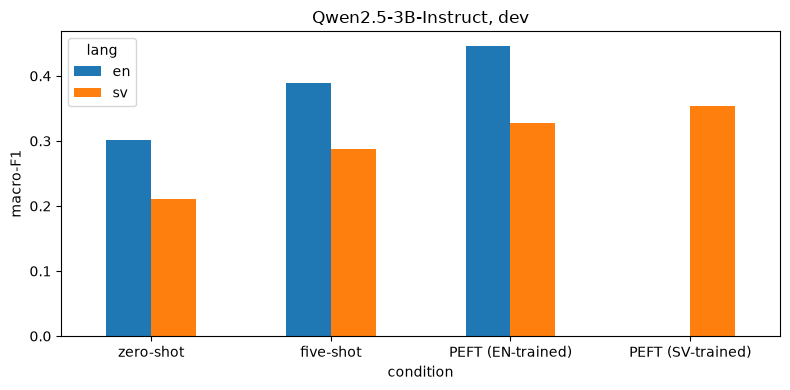

In [11]:
rows = []
for (l, c) in available:
    m = load_metrics(l, c)
    rows.append({"lang": l, "condition": c, "macro_f1": m["macro_f1"], "micro_f1": m["micro_f1"],
                 "samples_f1": m["samples_f1"], "jaccard": m["jaccard"], "exact_match": m["exact_match"],
                 "malformed": m["malformed_rate"], "empty": m["empty_prediction_rate"],
                 "labels/text": m["pred_label_cardinality"], "gold labels/text": m["gold_label_cardinality"]})
main = pd.DataFrame(rows)
order = {c: i for i, c in enumerate(CONDITIONS)}
main = main.sort_values(["lang", "condition"], key=lambda s: s.map(order) if s.name == "condition" else s)
display(main.set_index(["lang", "condition"]))

ax = main.pivot(index="condition", columns="lang", values="macro_f1").reindex(list(CONDITIONS)).plot.bar(rot=0, figsize=(8, 4))
ax.set_ylabel("macro-F1"); ax.set_title(f"Qwen2.5-3B-Instruct, {SPLIT}"); plt.tight_layout(); plt.show()

## 3. Paired bootstrap

1,000 resamples of the texts; both conditions are scored on the *same* resampled texts (matched by
alignment ID). If the 95% interval excludes 0, the difference is unlikely to be noise.
The cross-lingual rows compare English and Swedish versions of the same aligned texts.

In [ ]:
from llm_project.notebook_utils import binarise, f1s, paired_bootstrap

comparisons = []
for l in LANGS:
    for peft in ["PEFT (EN-trained)", "PEFT (SV-trained)"]:
        for base in ["zero-shot", "five-shot"]:
            comparisons.append((f"{peft} vs {base}", (l, base), (l, peft)))
comparisons.append(("SV-trained vs EN-trained (on SV)", ("sv", "PEFT (EN-trained)"), ("sv", "PEFT (SV-trained)")))
for c in CONDITIONS:
    comparisons.append((f"SV vs EN | {c}", ("en", c), ("sv", c)))

rows = []
for name, a, b in comparisons:
    if a not in available or b not in available:
        continue
    d, lo, hi, n = paired_bootstrap(available[a], available[b], labels=LABELS)
    rows.append({"comparison": name, "lang (A -> B)": f"{a[0]} -> {b[0]}", "macro_f1 diff (B-A)": d,
                 "ci_low": lo, "ci_high": hi, "significant": not (lo <= 0 <= hi), "n": n})
boot = pd.DataFrame(rows)
boot

,comparison,lang (A -> B),macro_f1 diff (B-A),ci_low,ci_high,significant,n
0,PEFT (EN-trained) vs zero-shot,en -> en,0.145,1.044e-01,0.185,True,497
1,PEFT (EN-trained) vs five-shot,en -> en,0.057,1.745e-02,0.096,True,497
2,PEFT (EN-trained) vs zero-shot,sv -> sv,0.117,7.964e-02,0.153,True,497
3,PEFT (EN-trained) vs five-shot,sv -> sv,0.039,-3.710e-04,0.075,False,497
4,PEFT (SV-trained) vs zero-shot,sv -> sv,0.143,1.085e-01,0.178,True,497
5,PEFT (SV-trained) vs five-shot,sv -> sv,0.065,2.911e-02,0.099,True,497
6,SV-trained vs EN-trained (on SV),sv -> sv,0.026,-1.505e-03,0.055,False,497
7,SV vs EN | zero-shot,en -> sv,-0.092,-1.284e-01,-0.054,True,497
8,SV vs EN | five-shot,en -> sv,-0.102,-1.338e-01,-0.066,True,497
9,SV vs EN | PEFT (EN-trained),en -> sv,-0.119,-1.630e-01,-0.077,True,497


## 4. Per-emotion F1
Which emotions does fine-tuning improve, and which transfer from English to Swedish?

en                                    sv            \
             zero-shot five-shot PEFT (EN-trained) zero-shot five-shot   
anger            0.321     0.483             0.631     0.170     0.375   
anticipation     0.388     0.467             0.536     0.280     0.387   
disgust          0.176     0.387             0.380     0.028     0.330   
fear             0.209     0.356             0.343     0.053     0.133   
joy              0.317     0.449             0.497     0.240     0.434   
sadness          0.422     0.451             0.483     0.389     0.279   
surprise         0.180     0.086             0.354     0.262     0.043   
trust            0.400     0.438             0.346     0.258     0.323   

                                                 gold_support_sv  
             PEFT (EN-trained) PEFT (SV-trained)                  
anger                    0.381             0.447             125  
anticipation             0.389             0.510             119  
disgust                  0.094             0.210              67  
fear                     0.291             0.308              67  
joy                      0.443             0.440              77  
sadness                  0.444             0.449              89  
surprise                 0.367             0.274              84  
trust                    0.207             0.190              87

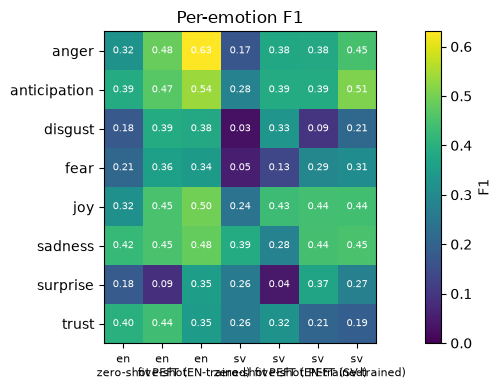

In [13]:
per = {}
for (l, c) in available:
    m = load_metrics(l, c)
    per[(l, c)] = {e: m["per_label"][e]["f1"] for e in LABELS}
per = pd.DataFrame(per)[[k for l in LANGS for k in [(l, c) for c in CONDITIONS] if k in available]]
first = next(iter(available))
per["gold_support_sv"] = [load_metrics("sv", "zero-shot")["per_label"][e]["support"] for e in LABELS] \
    if ("sv", "zero-shot") in available else np.nan
display(per)

f1_only = per.drop(columns="gold_support_sv")
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(f1_only.values, cmap="viridis", vmin=0, vmax=max(0.6, np.nanmax(f1_only.values)))
ax.set_yticks(range(len(LABELS)), LABELS)
ax.set_xticks(range(f1_only.shape[1]), [f"{l}\n{c}" for l, c in f1_only.columns], fontsize=8)
for i in range(f1_only.shape[0]):
    for j in range(f1_only.shape[1]):
        ax.text(j, i, f"{f1_only.iat[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w")
fig.colorbar(im, label="F1"); ax.set_title("Per-emotion F1"); plt.tight_layout(); plt.show()

## 5. Label counts and label distribution
How often each emotion is predicted, against how often it is gold.

In [14]:
for l in LANGS:
    runs = {c: available[(l, c)] for c in CONDITIONS if (l, c) in available}
    if not runs:
        continue
    gold = next(iter(runs.values()))["gold"]
    table = {"GOLD": pd.Series([e for g in gold for e in g]).value_counts().reindex(LABELS, fill_value=0)}
    for c, df in runs.items():
        table[c] = pd.Series([e for p in df["pred"] for e in p]).value_counts().reindex(LABELS, fill_value=0)
    print(f"--- {l}: predicted counts per emotion ---")
    display(pd.DataFrame(table))

--- en: predicted counts per emotion ---


,GOLD,zero-shot,five-shot,PEFT (EN-trained)
anger,125,43,86,154
anticipation,119,144,202,146
disgust,67,24,119,54
fear,67,19,34,32
joy,77,24,61,68
sadness,89,91,53,56
surprise,84,27,9,46
trust,87,93,137,40


--- sv: predicted counts per emotion ---


,GOLD,zero-shot,five-shot,PEFT (EN-trained),PEFT (SV-trained)
anger,125,28,83,132,166
anticipation,119,81,165,66,136
disgust,67,4,121,18,57
fear,67,8,8,43,37
joy,77,23,66,81,64
sadness,89,91,47,82,58
surprise,84,99,8,63,40
trust,87,91,99,29,29


## 6. Hard texts: wrong for every condition
Texts that no condition gets exactly right are often texts without an emotional cue (context lost from the film).

In [15]:
for l in LANGS:
    runs = {c: available[(l, c)] for c in CONDITIONS if (l, c) in available}
    if len(runs) < 2:
        continue
    ids = next(iter(runs.values())).index
    exact = pd.DataFrame({c: [set(df.at[i, "gold"]) == set(df.at[i, "pred"]) for i in ids] for c, df in runs.items()}, index=ids)
    print(f"--- {l}: texts exactly right per number of conditions ---")
    print(exact.sum(axis=1).value_counts().sort_index().to_string())
    hard = exact.index[~exact.any(axis=1)]
    print(f"{len(hard)} of {len(ids)} texts are wrong in every condition. Sample:")
    first_df = next(iter(runs.values()))
    with pd.option_context("display.max_colwidth", 90):
        display(first_df.loc[hard[:10], ["text", "gold"]].assign(**{c: runs[c].loc[hard[:10], "pred"] for c in runs}))

--- en: texts exactly right per number of conditions ---
0    305
1    102
2     52
3     38
305 of 497 texts are wrong in every condition. Sample:


,text,gold,zero-shot,five-shot,PEFT (EN-trained)
alignment_id,,,,,
en/1954/46754/6980377.xml.gz#1010,"I got him sold, Harry.",[joy],[anticipation],"[anticipation, joy]",[anticipation]
en/1954/46754/6980377.xml.gz#1330,"But no more odd, surely, than my driving away that day, away from her, knowing that, i...",[trust],[sadness],"[anticipation, sadness]",[sadness]
en/1954/46754/6980377.xml.gz#1335,You've cost me millions and millions of francs.,"[anger, disgust, sadness]",[anger],"[anger, disgust]",[anger]
en/1954/46754/6980377.xml.gz#1447,That to marry Maria would be the most senselessly cruel and destructive thing you will...,"[anger, fear, surprise]",[disgust],"[disgust, fear]","[anger, disgust]"
en/1954/46754/6980377.xml.gz#1458,Perhaps that's why I'm incapable of having a child.,[fear],[sadness],[sadness],[sadness]
en/1954/46754/6980377.xml.gz#1564,"Oh, no, no, no.","[anticipation, surprise]",[sadness],"[disgust, sadness]",[sadness]
en/1954/46754/6980377.xml.gz#1606,I do not know who plays the violin.,"[anticipation, fear]",[],[],[surprise]
en/1954/46754/6980377.xml.gz#1655,"Emotionally, she's a child.",[anger],[sadness],[sadness],[sadness]
en/1954/46754/6980377.xml.gz#1753,Do you understand now why it is so important to me for you to believe that I love you ...,[joy],[trust],"[anticipation, joy, trust]","[anger, anticipation]"


--- sv: texts exactly right per number of conditions ---
0    314
1     70
2     57
3     36
4     20
314 of 497 texts are wrong in every condition. Sample:


,text,gold,zero-shot,five-shot,PEFT (EN-trained),PEFT (SV-trained)
alignment_id,,,,,,
en/1954/46672/4170335.xml.gz#39,Inget passande ställe för en prästson.,"[anger, disgust]",[sadness],[disgust],[sadness],[anger]
en/1954/46754/6980377.xml.gz#1010,Jag knep honom.,[joy],[surprise],[disgust],[anger],[anger]
en/1954/46754/6980377.xml.gz#1174,Om det hade hjälpt hade jag skrikit det pa gatorna.,[anger],[surprise],"[anger, anticipation, disgust]",[fear],"[anger, disgust]"
en/1954/46754/6980377.xml.gz#1300,Han är mindre gigolo än nagon i vart sällskap.,[trust],[surprise],[disgust],[anger],[disgust]
en/1954/46754/6980377.xml.gz#1330,"Men det är inte underligare än att jag den dagen körde vidare, bort fran henne i vetsk...",[trust],[surprise],"[anticipation, sadness]","[anticipation, joy]","[anticipation, joy]"
en/1954/46754/6980377.xml.gz#1335,Du har kostat mig miljoner franc.,"[anger, disgust, sadness]",[sadness],"[anger, disgust]",[anger],[anger]
en/1954/46754/6980377.xml.gz#1434,- Det har jag insett.,[anticipation],[],[sadness],[sadness],[anger]
en/1954/46754/6980377.xml.gz#1447,Att gifta dig med Maria skulle vara det mest destruktiva du kan göra?,"[anger, fear, surprise]","[anger, trust]",[disgust],[fear],[fear]
en/1954/46754/6980377.xml.gz#1458,Kanske är det därför jag inte kan fa barn.,[fear],[sadness],"[sadness, trust]",[sadness],[sadness]


## 7. Swedish texts without å/ä/ö
Some subtitles lost their diacritics (e.g. *grata* for *gråta*). Does that hurt accuracy?

In [16]:
if ("sv", "zero-shot") in available:
    sv_text = available[("sv", "zero-shot")]["text"]
    no_diacritics = ~sv_text.str.lower().str.contains("[åäö]")
    print(f"{no_diacritics.sum()} of {len(sv_text)} Swedish texts contain no å/ä/ö "
          "(includes texts that simply don't need them)")
    rows = []
    for c in CONDITIONS:
        if ("sv", c) not in available:
            continue
        df = available[("sv", c)]
        for flag, label in [(no_diacritics, "no å/ä/ö"), (~no_diacritics, "has å/ä/ö")]:
            sub = df[flag.reindex(df.index).values]
            rows.append({"condition": c, "group": label, "n": len(sub),
                         "macro_f1": f1s(binarise(sub["gold"]), binarise(sub["pred"]))[0]})
    display(pd.DataFrame(rows).pivot(index="condition", columns="group", values="macro_f1"))
    with pd.option_context("display.max_colwidth", 90):
        display(sv_text[no_diacritics].head(20).to_frame())

94 of 497 Swedish texts contain no å/ä/ö (includes texts that simply don't need them)


group,has å/ä/ö,no å/ä/ö
condition,,
PEFT (EN-trained),0.330,0.307
PEFT (SV-trained),0.360,0.319
five-shot,0.296,0.238
zero-shot,0.216,0.161


,text
alignment_id,
en/1954/46754/6980377.xml.gz#1010,Jag knep honom.
en/1954/46754/6980377.xml.gz#1317,Ett universellt botemedel.
en/1954/46754/6980377.xml.gz#1335,Du har kostat mig miljoner franc.
en/1954/46754/6980377.xml.gz#1434,- Det har jag insett.
en/1954/46754/6980377.xml.gz#46,Dansar hon inte mer?
en/1954/46754/6980377.xml.gz#492,Han kan inte diskutera hennes framtid just nu.
en/1954/46754/6980377.xml.gz#766,Det ljusnade da Marias kanalje till bror gav sitt vittnesmal.
en/1954/46816/4245477.xml.gz#1236,- Tyckte ni om kapten Queeg?
en/1954/46816/4245477.xml.gz#806,- Paynter?
